# ANT-X 2-DOF rig: final code (MTR615, Aladem and Saleh)

This notebook makes every result on slides 12 to 16 of the talk, from the flight files in `data/`.

**Goal:** a simulator of the rig. It takes the state now and the command, and gives the state one step (0.02 s) later.

- **Job 1, find the constants of the physics equation:** the simulation fit, and the inverse PINN.
- **Job 2, the simulator.** Three are compared:
  - the equation, solved step by step with a solver;
  - a plain neural network (NN);
  - the PINC, which is the same network as the plain NN but is also trained to obey the equation.

| Slide | Result | Section |
|---|---|---|
| 12 | Motors off: constants, and VAF on the unseen flight | 6, 7 |
| 13 | Hover: VAF on unseen flights | 8 |
| 14 | Hover: commands that were never flown | 8 |
| 15 | Closed-loop position, and the PINC learning its own constants | 7 |
| 16 | Cart friction | 9 |

**House rules, used everywhere.** The one change: the rig's motors react one step late, so every model also gets the command from one step ago, `u_before`.
1. Each equation is written once, as `accel_...(z, v, u, constants)`. The solver and the PINC loss both use it.
2. Every model is `step(z, v, u, u_before)` → `(z, v)` at the next step. It comes from a solver factory (`pitch_model`, `cl_model`, `cart_model`) or from `pinc_model(net, ...)`.
3. One runner for any model, `run_open(step, u_list, z0, v0)`. There is no PID experiment in this study, so `run_pid` is not needed.
4. Every network is `mlp(n_in, n_out)`, with its inputs passed through `col(x)`.
5. Every training function has four parts (data, network, optimizer, loop), names its losses `physics`, `data` and `loss`, and returns a dict.

**Names:** `z` is the position (pitch θ, or cart position x), `v` is its rate (pitch rate q, or cart speed), and `u` is the input (motor command M, position setpoint, or pitch θ).

**Score:** VAF = 1 − var(measured − model) / var(measured), in %. 100 % is perfect. Every score is on a flight the model never saw in training.

**Run time:** about 1 hour on a 4-core CPU, almost all of it network training. Packages: numpy, pandas, scipy, torch, matplotlib.

## 0. Setup

In [1]:
import time                                    # to measure training time
import numpy as np                             # arrays and maths
import pandas as pd                            # tables (the flight files are csv)
import torch                                   # neural networks + automatic derivatives
import matplotlib.pyplot as plt                # plots
from scipy.integrate import solve_ivp          # ODE solver: the "equation" simulator
from scipy.optimize import least_squares       # used by the simulation fit
from scipy.signal import savgol_filter         # smoothed derivative (for the acceleration score)

torch.set_num_threads(4)                       # use up to 4 CPU cores

DATA = '../data/'      # folder with the flight files
DT = 0.02              # one step = 0.02 s (50 Hz)
TAU = 0.02             # motor delay of the rig = exactly one step
SEEDS = [0, 1, 2, 3, 4]   # every network is trained 5 times, from 5 random starts
EPOCHS = 10000         # training passes per network


def vaf(y, y_model):
    # Variance Accounted For, in %: 100 = perfect, 0 = no better than a flat line
    return max(1 - np.var(y - y_model) / np.var(y), 0) * 100


def acc(v):
    # acceleration from a speed signal: slope, smoothed over 0.5 s (25 samples)
    return savgol_filter(v, 25, 2, deriv=1, delta=DT)

## 1. Data
Every flight is turned into the same table, with columns `t`, `z`, `v` and `u`, one row per step.

| Case | Rig | z, v | u | Train | Test |
|---|---|---|---|---|---|
| motors off | 1-DOF pitch: one push, then a free swing | θ, q | M | impulse_1-4 | impulse_5 |
| CL position | 2-DOF, with the rig's own position controller on | x, speed | x setpoint | position_1, 3 | position_2 |
| cart | 2-DOF, the cart driven by the measured pitch | x, speed | θ | velocity_doublet_2, 3, position_1, 3 | velocity_doublet_4, position_2 |
| hover | 1-DOF pitch, motors on, doublet command | θ, q | M | doublet_1-4 | doublet_5, 6 |

The hover flights are loaded in section 8.

In [2]:
def load_clean(kind, name, z_col, v_col, u_col):
    # cleaned flight (250 Hz); keep every 5th row so one row = one step of DT
    f = pd.read_csv(f'{DATA}clean/{kind}/{name}.csv')
    f = f.iloc[::5].reset_index(drop=True)
    return pd.DataFrame(dict(t=f.t, z=f[z_col], v=f[v_col], u=f[u_col]))


# motors off: pitch theta [rad], pitch rate q [rad/s], motor command M
IMPULSE = {}
for i in range(1, 6):
    name = f'impulse_{i}'
    IMPULSE[name] = load_clean('1dof', name, 'theta', 'q', 'M')

# closed-loop position: cart x [m], speed v [m/s], position setpoint x_sp [m]
POSITION = {}
for name in ['position_1', 'position_2', 'position_3']:
    POSITION[name] = load_clean('2dof', name, 'x', 'v', 'x_sp')

# cart driven by pitch: cart x [m], speed v [m/s], measured pitch theta [rad]
CART = {}
for name in ['velocity_doublet_2', 'velocity_doublet_3', 'velocity_doublet_4', 'position_1', 'position_2', 'position_3']:
    CART[name] = load_clean('2dof', name, 'x', 'v', 'theta')

for group in [IMPULSE, POSITION, CART]:
    print({name: len(f) for name, f in group.items()}, 'rows')

{'impulse_1': 300, 'impulse_2': 300, 'impulse_3': 300, 'impulse_4': 300, 'impulse_5': 300} rows
{'position_1': 1925, 'position_2': 2177, 'position_3': 1570} rows
{'velocity_doublet_2': 1236, 'velocity_doublet_3': 1174, 'velocity_doublet_4': 1117, 'position_1': 1925, 'position_2': 2177, 'position_3': 1570} rows


## 2. Physics, written once
- **Pitch** (ANT-X 1-DOF model): θ'' = −2ξωn·q − ωn²(θ − θ0) + μ·M(t − 0.02).
  ωn is the stiffness, ξ the damping, μ the motor gain and θ0 the rest angle. The motors react 0.02 s late.
- **Closed-loop position** (thesis model): x'' = ωn²(x_sp − x) − 2ξωn·v. The rig's own controller pulls the cart toward the setpoint.
- **Cart** (Amr's model plus our friction): v' = −c̄·v − k̄(θ − θb) − Fc·tanh(v / 0.01).
  - The tilt pushes the cart, and c̄ is drag.
  - Fc is a constant rubbing force against the motion. tanh(v / 0.01) is a smooth sign of v.
  - θb is a small tilt of the rig itself.
  - With Fc = θb = 0 this is Amr's linear model.

The pitch and position functions work with numpy (the solver) and with torch (the PINC loss).

In [3]:
def accel_pitch(z, v, u, wn, xi, mu, th0):
    # pitch acceleration: damping + spring back to th0 + motor push
    return -2 * xi * wn * v - wn**2 * (z - th0) + mu * u


def accel_cl(z, v, u, wn, xi):
    # closed-loop position: the controller pulls x to the setpoint u, with damping
    return wn**2 * (u - z) - 2 * xi * wn * v


def accel_cart(z, v, u, kbar, cbar, Fc=0.0, thb=0.0):
    # cart: pitch u pushes, drag cbar, rubbing force Fc, rig tilt thb
    return -cbar * v - kbar * (u - thb) - Fc * np.tanh(v / 0.01)

## 3. The equation as a model, and the runner
**Delay inside a step.** The motors react exactly one step late. During the step from t to t + DT, the command the rig feels therefore slides from `u_before` (sent one step ago) to `u` (sent now).
`felt_command` gives that command at a time s inside the step. With no delay (tau = 0) it is just `u`.

Each factory builds a `step(z, v, u, u_before)` that solves the equation over one step with `solve_ivp`.
`run_open` then plays a whole flight: it starts from the first measured state, and each output becomes the next input. There is no correction from the measurements.

In [4]:
def felt_command(u, u_before, s, tau):
    # command felt by the rig at time s (0..DT) inside a step, for a delay of tau (up to one step)
    w = min(tau / DT, 1.0)
    return u - w * (1 - s / DT) * (u - u_before)


def pitch_model(wn, xi, mu, th0, tau=TAU):
    # the pitch equation as a model: step(z, v, u, u_before) -> (z, v) one step later
    def step(z, v, u, u_before):
        def rhs(s, state):
            u_s = felt_command(u, u_before, s, tau)
            return [state[1], accel_pitch(state[0], state[1], u_s, wn, xi, mu, th0)]
        end = solve_ivp(rhs, (0, DT), [z, v], max_step=DT / 4).y[:, -1]
        return end[0], end[1]
    return step


def cl_model(wn, xi):
    # the closed-loop position equation as a model (no delay)
    def step(z, v, u, u_before):
        rhs = lambda s, state: [state[1], accel_cl(state[0], state[1], u, wn, xi)]
        end = solve_ivp(rhs, (0, DT), [z, v], max_step=DT / 4).y[:, -1]
        return end[0], end[1]
    return step


def cart_model(kbar, cbar, Fc=0.0, thb=0.0):
    # the cart equation as a model (input = measured pitch, no delay)
    def step(z, v, u, u_before):
        rhs = lambda s, state: [state[1], accel_cart(state[0], state[1], u, kbar, cbar, Fc, thb)]
        end = solve_ivp(rhs, (0, DT), [z, v], max_step=DT / 4).y[:, -1]
        return end[0], end[1]
    return step


def run_open(step, u_list, z0, v0):
    # OPEN LOOP: play a list of inputs, one per step, from the start state (z0, v0)
    z, v = z0, v0
    z_list, v_list = [z], [v]
    for k in range(len(u_list) - 1):
        u_before = u_list[k - 1] if k > 0 else u_list[0]
        z, v = step(z, v, u_list[k], u_before)     # the model moves one step
        z_list.append(z)
        v_list.append(v)
    return np.array(z_list), np.array(v_list)


def run_flight(step, f, u_list=None):
    # run_open on a recorded flight: start from its first state, play its inputs (or new ones)
    u_list = f.u.values if u_list is None else u_list
    return run_open(step, u_list, f.z[0], f.v[0])

## 4. The network as a model
`pinc_model(net, scale)` builds the same `step(z, v, u, u_before)` from a network. It works like this:
- the inputs (z, v, u, u_before) are scaled to about −1..1, and the time dt (0 to DT) is the fifth input;
- the network gives the **change** of z and v after dt, so dt = DT is one normal step;
- `step.torch` is the same function on torch columns, with dt free. Training uses it to check the physics inside a step.

The PINC and the plain NN are the same network. Only their training differs.

In [5]:
def mlp(n_in, n_out, width=32, depth=3):
    # the network body used everywhere: n_in inputs -> depth hidden layers of width tanh neurons -> n_out outputs
    layers = [torch.nn.Linear(n_in, width), torch.nn.Tanh()]
    for _ in range(depth - 1):
        layers += [torch.nn.Linear(width, width), torch.nn.Tanh()]
    layers += [torch.nn.Linear(width, n_out)]
    return torch.nn.Sequential(*layers)


def col(x):
    # a number, list or array -> float32 column tensor (n rows x 1 column)
    return torch.as_tensor(np.asarray(x), dtype=torch.float32).view(-1, 1)


def derivative(y, x):
    # dy/dx with autograd (create_graph=True so it can be used inside a loss)
    return torch.autograd.grad(y, x, torch.ones_like(y), create_graph=True)[0]


def pinc_model(net, scale):
    # scale: mean and spread of the 4 inputs, and the typical change of z and v in one step
    def step_torch(z, v, u, u_before, dt):
        x = torch.cat([(z - scale['mean'][0]) / scale['std'][0],
                       (v - scale['mean'][1]) / scale['std'][1],
                       (u - scale['mean'][2]) / scale['std'][2],
                       (u_before - scale['mean'][3]) / scale['std'][3],
                       dt / DT], dim=1)
        out = net(x)                                          # 2 outputs: change of z, change of v
        return z + scale['change'][0] * out[:, 0:1], v + scale['change'][1] * out[:, 1:2]

    def step(z, v, u, u_before):
        with torch.no_grad():                                 # prediction only, no training
            z_new, v_new = step_torch(col([z]), col([v]), col([u]), col([u_before]), col([DT]))
        return z_new.item(), v_new.item()

    step.torch = step_torch
    return step

## 5. Training functions
**Simulation fit** (Job 1). Least squares picks the constants so that `run_flight` of the equation matches each whole train flight.

**Inverse PINN** (Job 1). One flight is fitted by a small network θ(t), and its first and second time derivatives must obey the pitch equation. The constants are trained together with the network. It is run once per train flight, and the constants are averaged.

**PINC** (Job 2). The loss has three parts, all trained together:
- `data`: one step from a measured state must land on the next measured state;
- `start`: with dt = 0 nothing may change;
- `physics`: 2,000 made-up states (new random ones every epoch, in the train range plus 20 %) must obey the equation at a random time dt inside the step.

`w_phys = 0` switches off the physics, which gives the **plain NN**. `learn=True` keeps training the constants, starting from the simulation fit.

In [6]:
def train_sim_fit(make_model, names, flights, x0, lo, hi, match='z'):
    # 1) data: the train flights
    train = [flights[n] for n in names]
    keys = list(x0)                                         # names of the constants, e.g. wn, xi, mu, th0
    start = time.perf_counter()

    # 2) the error for a guess of the constants: simulated - measured, all train flights joined
    def errors(values):
        step = make_model(**dict(zip(keys, values)))
        out = []
        for f in train:
            z, v = run_flight(step, f)
            out.append((z if match == 'z' else v) - f[match].values)
        return np.concatenate(out)

    # 3) least squares moves the constants until the error is smallest
    r = least_squares(errors, list(x0.values()), bounds=(lo, hi))
    return dict(constants=dict(zip(keys, r.x)), secs=time.perf_counter() - start)

In [7]:
def train_inverse_pinn(f, steps=30000, lr=1e-3, w_data=3000.0, seed=0):
    torch.manual_seed(seed)
    # 1) data: one flight at 250 Hz, as columns; time scaled to -1..1, pitch scaled by 0.3 rad
    T, S = f.t.values[-1], 0.3
    t, y = col(f.t.values), col(f.theta.values)
    M_felt = col(np.interp(f.t.values - TAU, f.t.values, f.M.values))    # command delayed by TAU
    # 2) network theta(t) + the 4 unknown constants (wn, xi, mu trained as log so they stay positive)
    net = mlp(1, 1)
    theta_of = lambda t: S * net(2 * t / T - 1)
    raw = {'wn': np.log(3.0), 'xi': np.log(0.1), 'mu': np.log(50.0), 'th0': 0.0}
    raw = {k: torch.nn.Parameter(torch.tensor(float(x))) for k, x in raw.items()}
    constants = lambda: dict(wn=raw['wn'].exp(), xi=raw['xi'].exp(), mu=raw['mu'].exp(), th0=raw['th0'])
    # 3) optimizer: Adam, learning rate falling from lr to lr/20 (cosine)
    opt = torch.optim.Adam(list(net.parameters()) + list(raw.values()), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps, eta_min=lr / 20)
    # 4) training loop
    for i in range(steps):
        t_phys = t.clone().requires_grad_(True)
        th = theta_of(t_phys)                       # pitch
        q = derivative(th, t_phys)                  # pitch rate theta'
        a = derivative(q, t_phys)                   # pitch acceleration theta''
        physics = (((a - accel_pitch(th, q, M_felt, **constants())) / S)**2).mean()
        data = (((th - y) / S)**2).mean()           # match the measured pitch
        loss = physics + w_data * data
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    found = {k: float(x.detach()) for k, x in constants().items()}
    return dict(constants=found, physics=physics.item(), data=data.item())

In [8]:
POSITIVE = ['wn', 'xi', 'mu']            # learned constants that must stay positive (trained as log)


def train_pinc(flights, names, accel, constants, tau, seed=0, epochs=EPOCHS, lr=1e-3, w_phys=1.0, learn=False, n_phys=2000):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    # 1) data: one-step examples (z_k, v_k, u_k, u_k-1) -> (z_k+1, v_k+1) from every train flight
    rows = []
    for n in names:
        f = flights[n]
        z, v, u = f.z.values, f.v.values, f.u.values
        rows.append(np.column_stack([z[1:-1], v[1:-1], u[1:-1], u[:-2], z[2:], v[2:]]))
    A = np.vstack(rows)
    scale = dict(mean=A[:, :4].mean(0), std=A[:, :4].std(0) + 1e-6, change=(A[:, 4:6] - A[:, :2]).std(0))
    z0, v0, u0, ub0, z1, v1 = [col(A[:, i]) for i in range(6)]
    low, high = A[:, :4].min(0), A[:, :4].max(0)
    pad = 0.2 * (high - low)                                    # made-up states: train range + 20 %
    # 2) network (+ the constants, if they are learned)
    net = mlp(5, 2)
    step = pinc_model(net, scale).torch
    raw = {k: torch.nn.Parameter(torch.tensor(float(np.log(max(x, 1e-3)) if k in POSITIVE else x))) for k, x in constants.items()}
    if learn:
        consts = lambda: {k: (x.exp() if k in POSITIVE else x) for k, x in raw.items()}
    else:
        consts = lambda: constants
    # 3) optimizer
    params = list(net.parameters()) + (list(raw.values()) if learn else [])
    opt = torch.optim.Adam(params, lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs, eta_min=lr / 20)
    # 4) training loop (full batch: one update per epoch)
    d = scale['change']
    for e in range(epochs):
        z, v = step(z0, v0, u0, ub0, torch.full_like(z0, DT))           # one step from measured states
        data = (((z - z1) / d[0])**2).mean() + (((v - v1) / d[1])**2).mean()
        z, v = step(z0, v0, u0, ub0, torch.zeros_like(z0))              # dt = 0 -> no change
        start = (((z - z0) / d[0])**2).mean() + (((v - v0) / d[1])**2).mean()
        physics = torch.tensor(0.0)
        if w_phys > 0:
            made_up = [col(rng.uniform(low[i] - pad[i], high[i] + pad[i], n_phys)) for i in range(4)]
            dt = col(rng.uniform(0, DT, n_phys)).requires_grad_(True)
            z, v = step(*made_up, dt)
            dz, dv = derivative(z, dt), derivative(v, dt)                # rates of change inside the step
            u_s = felt_command(made_up[2], made_up[3], dt, tau)
            physics = (((dz - v) * DT / d[0])**2).mean() + (((dv - accel(z, v, u_s, **consts())) * DT / d[1])**2).mean()
        loss = data + start + w_phys * physics
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    found = {k: float(x.detach()) if torch.is_tensor(x) else float(x) for k, x in consts().items()}
    return dict(step=pinc_model(net, scale), constants=found, data=data.item(), physics=physics.item())

## 6. Job 1: the constants (slide 12)
The simulation fit is run on the motors-off flights and on the closed-loop position flights. The inverse PINN is run on each motors-off train flight.
The ANT-X published values (Panza 2020) are listed for comparison. They come from a different rig.

In [9]:
TRAIN_IMP, TEST_IMP = ['impulse_1', 'impulse_2', 'impulse_3', 'impulse_4'], ['impulse_5']
TRAIN_POS, TEST_POS = ['position_1', 'position_3'], ['position_2']

fit = train_sim_fit(pitch_model, TRAIN_IMP, IMPULSE,
                    x0=dict(wn=4.0, xi=0.2, mu=80, th0=0), lo=[0.5, 0, 0, -0.3], hi=[20, 2, 2000, 0.3])
P_IMP = fit['constants']
print('motors off, simulation fit:', {k: round(x, 4) for k, x in P_IMP.items()}, f"({fit['secs']:.0f} s)")

fit = train_sim_fit(cl_model, TRAIN_POS, POSITION, x0=dict(wn=2.3, xi=1.1), lo=[0.5, 0], hi=[60, 3])
P_POS = fit['constants']
print('CL position, simulation fit:', {k: round(x, 4) for k, x in P_POS.items()}, f"({fit['secs']:.0f} s)")

motors off, simulation fit: {'wn': np.float64(4.065), 'xi': np.float64(0.2123), 'mu': np.float64(76.9296), 'th0': np.float64(0.0007)} (11 s)


CL position, simulation fit: {'wn': np.float64(2.2982), 'xi': np.float64(1.1419)} (13 s)


In [10]:
INV = {}
for n in TRAIN_IMP:
    f = pd.read_csv(f'{DATA}clean/1dof/{n}.csv')            # full 250 Hz flight
    start = time.perf_counter()
    INV[n] = train_inverse_pinn(f)
    print(n, {k: round(x, 3) for k, x in INV[n]['constants'].items()}, f'({time.perf_counter() - start:.0f} s)')

P_INV = {k: np.mean([r['constants'][k] for r in INV.values()]) for k in ['wn', 'xi', 'mu', 'th0']}
ANTX = dict(wn=3.437, xi=0.0836, mu=358.5, th0=0.0)

table = pd.DataFrame({'ANT-X published': ANTX, 'simulation fit': P_IMP, 'inverse PINN (mean of 4)': P_INV}).T
spread = {k: np.std([r['constants'][k] for r in INV.values()]) for k in ['wn', 'xi', 'mu']}
table['inverse PINN spread (std)'] = ['', '', f"wn {spread['wn']:.3f}, xi {spread['xi']:.3f}, mu {spread['mu']:.1f}"]
table.round(4)

/tmp/ipykernel_218/1345593229.py:12: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:208.)
  return torch.as_tensor(np.asarray(x), dtype=torch.float32).view(-1, 1)


impulse_1 {'wn': 4.026, 'xi': 0.15, 'mu': 60.836, 'th0': 0.015} (167 s)


impulse_2 {'wn': 4.022, 'xi': 0.157, 'mu': 68.397, 'th0': -0.0} (144 s)


impulse_3 {'wn': 4.017, 'xi': 0.16, 'mu': 62.557, 'th0': -0.006} (136 s)


impulse_4 {'wn': 4.06, 'xi': 0.168, 'mu': 64.919, 'th0': 0.003} (138 s)


,wn,xi,mu,th0,inverse PINN spread (std)
ANT-X published,3.437,0.0836,358.5000,0.0000,
simulation fit,4.065,0.2123,76.9296,0.0007,
inverse PINN (mean of 4),4.031,0.1587,64.1771,0.0029,"wn 0.017, xi 0.006, mu 2.8"


## 7. Job 2: the simulators on unseen flights (slides 12, 15)
Each network is trained with 5 seeds. The table gives the VAF of the whole-flight run on the test flight as mean ± std over the 5 seeds. The median is also given, because one seed that runs away does not pull it down.

The three networks:
- **plain NN**: physics off;
- **PINC**: physics on, with the simulation-fit constants;
- **PINC, learned constants**: physics on, and the constants keep training together with the network.

For the closed-loop position case the table also scores acceleration, because position alone is easy (every model is above 99 %).

In [11]:
CASES = {
    'motors off': dict(flights=IMPULSE, train=TRAIN_IMP, test=TEST_IMP, accel=accel_pitch, tau=TAU, constants=P_IMP),
    'CL position': dict(flights=POSITION, train=TRAIN_POS, test=TEST_POS, accel=accel_cl, tau=0.0, constants=P_POS),
}
NETWORKS = {
    'plain NN': dict(w_phys=0.0),
    'PINC': dict(w_phys=1.0),
    'PINC, learned constants': dict(w_phys=1.0, learn=True),
}

RUNS = {}
for case, c in CASES.items():
    for label, options in NETWORKS.items():
        start = time.perf_counter()
        RUNS[(case, label)] = [train_pinc(c['flights'], c['train'], c['accel'], c['constants'], c['tau'], seed=s, **options)
                               for s in SEEDS]
        print(f'{case:12s} {label:24s} {time.perf_counter() - start:5.0f} s')

motors off   plain NN                   125 s


motors off   PINC                       326 s


motors off   PINC, learned constants    346 s


CL position  plain NN                   176 s


CL position  PINC                       375 s


CL position  PINC, learned constants    368 s


In [12]:
def scores(f, z, v, case):
    out = dict(VAF_z=vaf(f.z.values, z))
    if case == 'CL position':
        out['VAF_acc'] = vaf(acc(f.v.values), acc(v))
    return out


SOLVERS = {
    'motors off': {'solver, simulation-fit constants': pitch_model(**P_IMP),
                   'solver, inverse-PINN constants': pitch_model(**P_INV),
                   'solver, ANT-X published constants': pitch_model(**ANTX)},
    'CL position': {'solver, simulation-fit constants': cl_model(**P_POS),
                    'solver, thesis constants (Ghezzi)': cl_model(wn=3.47, xi=0.84)},
}

rows = []
for case, c in CASES.items():
    for n in c['test']:
        f = c['flights'][n]
        for label, step in SOLVERS[case].items():
            rows.append(dict(case=case, test=n, model=label, **scores(f, *run_flight(step, f), case)))
        for label in NETWORKS:
            s = pd.DataFrame([scores(f, *run_flight(r['step'], f), case) for r in RUNS[(case, label)]])
            text = {k: f'{s[k].mean():.1f} ± {s[k].std():.1f} (median {s[k].median():.1f})' for k in s}
            rows.append(dict(case=case, test=n, model=label + ' (5 seeds)', **text))

VAF_TABLE = pd.DataFrame(rows).round(1)
VAF_TABLE.to_csv('final_vaf.csv', index=False)
pd.set_option('display.width', 200)
VAF_TABLE

,case,test,model,VAF_z,VAF_acc
0,motors off,impulse_5,"solver, simulation-fit constants",96.914983,NaN
1,motors off,impulse_5,"solver, inverse-PINN constants",94.331876,NaN
2,motors off,impulse_5,"solver, ANT-X published constants",0,NaN
3,motors off,impulse_5,plain NN (5 seeds),99.8 ± 0.0 (median 99.8),NaN
4,motors off,impulse_5,PINC (5 seeds),99.3 ± 0.1 (median 99.3),NaN
5,motors off,impulse_5,"PINC, learned constants (5 seeds)",99.3 ± 0.1 (median 99.3),NaN
6,CL position,position_2,"solver, simulation-fit constants",99.291186,69.437121
7,CL position,position_2,"solver, thesis constants (Ghezzi)",93.11661,0
8,CL position,position_2,plain NN (5 seeds),79.7 ± 44.6 (median 99.6),77.0 ± 43.1 (median 96.3)
9,CL position,position_2,PINC (5 seeds),99.4 ± 0.0 (median 99.3),85.5 ± 0.6 (median 85.7)


In [13]:
# constants the PINC learned (mean ± std over the 5 seeds), next to the simulation fit
rows = []
for case, c in CASES.items():
    runs = RUNS[(case, 'PINC, learned constants')]
    rows.append(dict(case=case, model='simulation fit', **{k: f'{x:.3f}' for k, x in c['constants'].items()}))
    learned = {k: f"{np.mean([r['constants'][k] for r in runs]):.3f} ± {np.std([r['constants'][k] for r in runs]):.3f}" for k in c['constants']}
    rows.append(dict(case=case, model='PINC, learned', **learned))
pd.DataFrame(rows).fillna('')

,case,model,wn,xi,mu,th0
0,motors off,simulation fit,4.065,0.212,76.930,0.001
1,motors off,"PINC, learned",3.966 ± 0.013,0.139 ± 0.002,65.763 ± 0.095,-0.004 ± 0.000
2,CL position,simulation fit,2.298,1.142,,
3,CL position,"PINC, learned",1.553 ± 0.006,0.729 ± 0.003,,


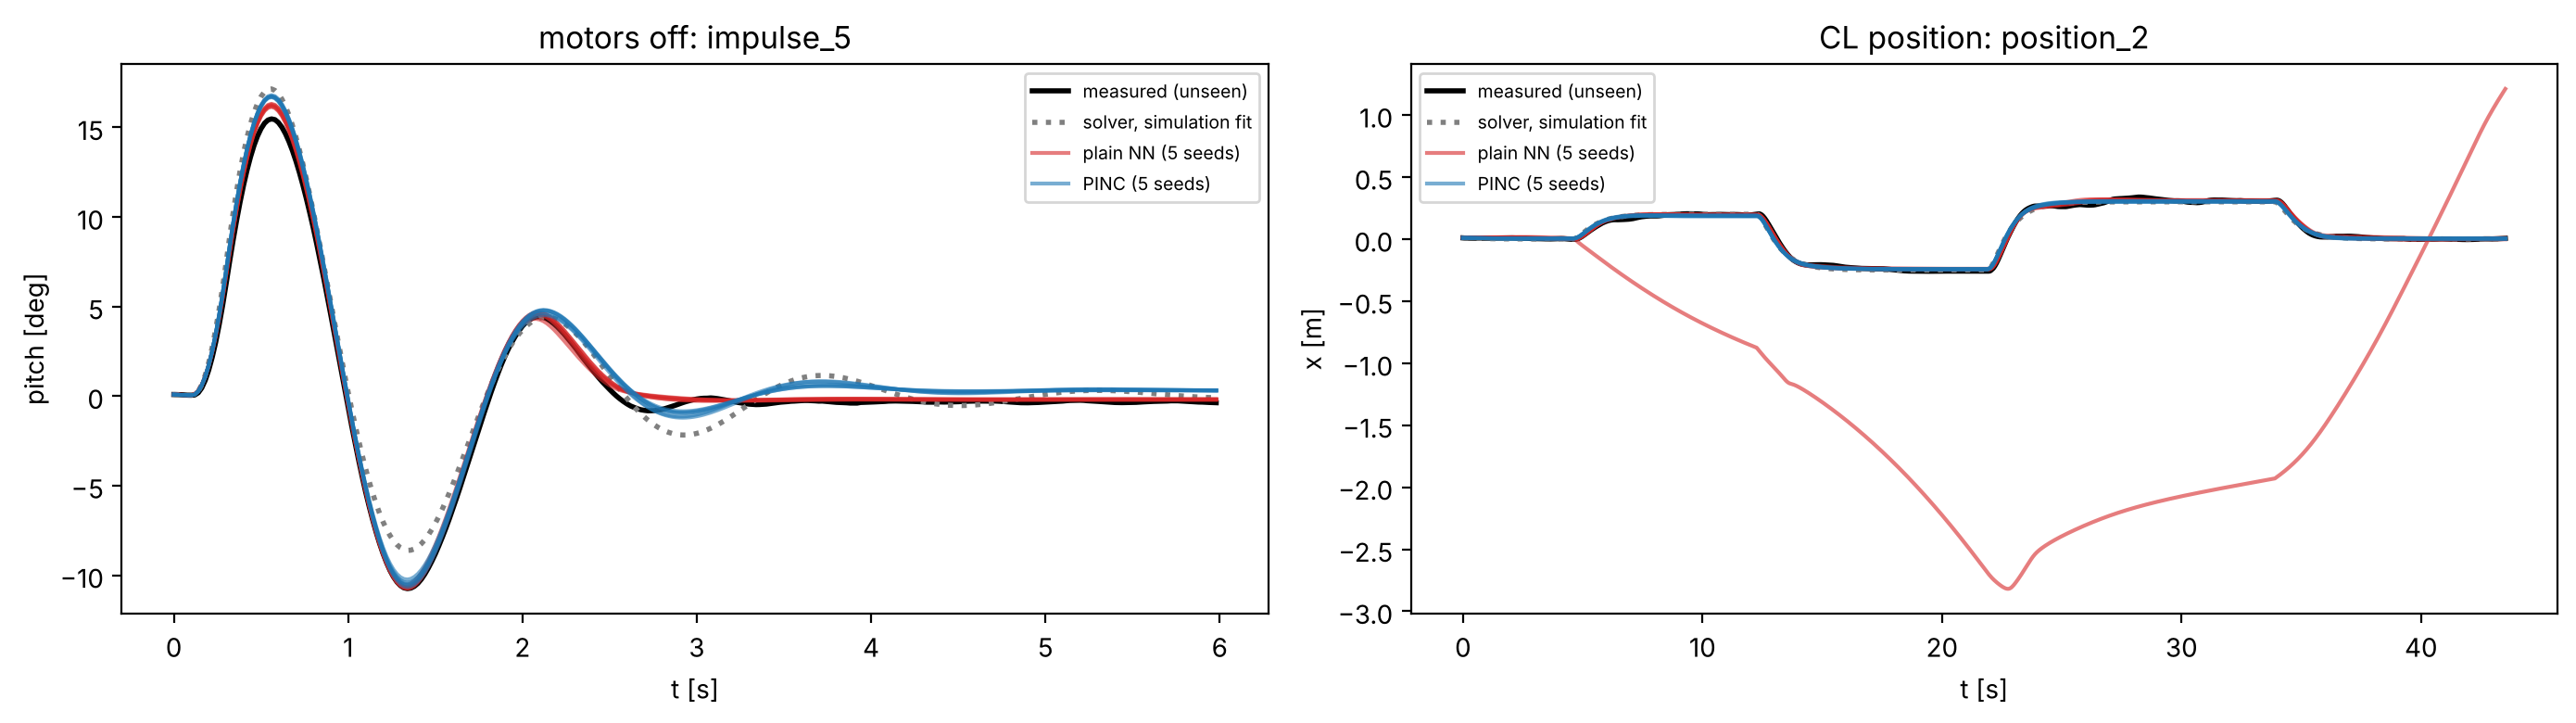

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, (case, n) in zip(ax, [('motors off', 'impulse_5'), ('CL position', 'position_2')]):
    c = CASES[case]
    f = c['flights'][n]
    unit = (lambda x: x) if case == 'CL position' else np.degrees       # show pitch in degrees
    a.plot(f.t, unit(f.z), 'k', lw=2, label='measured (unseen)')
    a.plot(f.t, unit(run_flight(SOLVERS[case]['solver, simulation-fit constants'], f)[0]), ':', color='gray', lw=2, label='solver, simulation fit')
    for label, color in [('plain NN', 'C3'), ('PINC', 'C0')]:
        for i, r in enumerate(RUNS[(case, label)]):
            a.plot(f.t, unit(run_flight(r['step'], f)[0]), color=color, alpha=0.6, label=label + ' (5 seeds)' if i == 0 else None)
    a.set(title=f'{case}: {n}', xlabel='t [s]', ylabel='x [m]' if case == 'CL position' else 'pitch [deg]')
    a.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 8. Hover: unseen flights and commands never flown (slides 13, 14)
The hover flights are short, about 1.5 s each, so there are only about 290 training steps in total. Slides 13 and 14 used a slightly different set-up for them:
- The delay is built into the input itself. `u` is the command the rig feels during the step, which is M(t − 0.02) averaged over the step. So the model has no delay (tau = 0), and `u_before` is not used.
- The network outputs the state after dt directly, not the change. It uses fixed scales: 0.3 rad, 4 rad/s and 0.06.
- The made-up physics states come from fixed ranges (±0.35 rad, ±4 rad/s, ±0.06), and dt = 0 is checked there too.
- Training runs for 20,000 epochs.

The constants come from a simulation fit over the whole 250 Hz train flights.

Then come two commands that were never flown, both on doublet_6: the doublet made 1.5 times bigger, and the command held 0.03 above trim for 1 s.
No flight exists for these, so the reference is the solver with the simulation-fit constants. It therefore scores 100 by definition.

In [15]:
FLIGHTS_1DOF = pd.read_csv(DATA + '1dof/flights_1dof.csv').set_index('file')    # when each doublet starts


def load_hover_raw(name):
    # 250 Hz window: from 0.1 s before the doublet to just before the pilot's motor kick-back
    info = FLIGHTS_1DOF.loc[name + '.csv']
    df = pd.read_csv(DATA + '1dof/' + name + '.csv')
    after = df[df.t > info.inj_start_s + 0.7]
    end = after.t[after.M.abs() > 0.12].iloc[0] - 0.05
    f = df[(df.t >= info.inj_start_s - 0.1 - TAU) & (df.t < end)].reset_index(drop=True)
    f['t'] = f.t - f.t[0] - TAU                  # time 0 = 0.1 s before the doublet (TAU extra kept for the delay)
    return f


def to_steps(f):
    # one row per DT; u = command felt during the step = M(t - TAU) averaged over the step
    t = np.arange(0, f.t.iloc[-1] - DT, DT)
    u = [np.mean(np.interp(np.linspace(ti, ti + DT, 6)[:-1] - TAU, f.t, f.M)) for ti in t]
    return pd.DataFrame(dict(t=t, z=np.interp(t, f.t, f.theta), v=np.interp(t, f.t, f.q), u=u))


HOVER_RAW, HOVER = {}, {}
for i in range(1, 7):
    name = f'doublet_{i}'
    HOVER_RAW[name] = load_hover_raw(name)
    HOVER[name] = to_steps(HOVER_RAW[name])
TRAIN_HOV, TEST_HOV = ['doublet_1', 'doublet_2', 'doublet_3', 'doublet_4'], ['doublet_5', 'doublet_6']


def solve_whole_flight(f, wn, xi, mu, th0):
    # solver over a whole 250 Hz flight from t = 0, with the measured M delayed by TAU (used for the fit)
    t, M = f.t.values, f.M.values
    i0 = np.searchsorted(t, 0.0)
    rhs = lambda s, state: [state[1], accel_pitch(state[0], state[1], np.interp(s - TAU, t, M), wn, xi, mu, th0)]
    return solve_ivp(rhs, (t[i0], t[-1]), [f.theta[i0], f.q[i0]], t_eval=t[i0:], max_step=0.004).y[0], i0


def errors(values):
    out = []
    for n in TRAIN_HOV:
        theta, i0 = solve_whole_flight(HOVER_RAW[n], *values)
        out.append(theta - HOVER_RAW[n].theta.values[i0:])
    return np.concatenate(out)


r = least_squares(errors, [3.8, 0.15, 180, -0.15], bounds=([0.5, 0, 0, -0.5], [20, 2, 2000, 0.5]))
P_HOV = dict(zip(['wn', 'xi', 'mu', 'th0'], r.x))
print('hover simulation fit:', {k: round(x, 4) for k, x in P_HOV.items()})

hover simulation fit: {'wn': np.float64(3.748), 'xi': np.float64(0.1158), 'mu': np.float64(190.1398), 'th0': np.float64(-0.1705)}


In [16]:
Z_SCALE, V_SCALE, U_SCALE = 0.3, 4.0, 0.06      # fixed scales: inputs and outputs about -1..1


def pinc_model_hover(net):
    # network model: inputs (z, v, u, dt) scaled; output = the state after dt
    def step_torch(z, v, u, dt):
        out = net(torch.cat([z / Z_SCALE, v / V_SCALE, u / U_SCALE, dt / DT], dim=1))
        return Z_SCALE * out[:, 0:1], V_SCALE * out[:, 1:2]

    def step(z, v, u, u_before):                    # same shape as every other model (u_before not used)
        with torch.no_grad():
            z_new, v_new = step_torch(col([z]), col([v]), col([u]), col([DT]))
        return z_new.item(), v_new.item()

    step.torch = step_torch
    return step


def train_pinc_hover(constants, seed=0, epochs=20000, lr=1e-3, w_phys=1.0, n_phys=2000):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    # 1) data: one-step examples (z_k, v_k, u_k) -> (z_k+1, v_k+1)
    train = [HOVER[n] for n in TRAIN_HOV]
    z0, v0, u0 = [col(np.concatenate([f[k].values[:-1] for f in train])) for k in ['z', 'v', 'u']]
    z1, v1 = [col(np.concatenate([f[k].values[1:] for f in train])) for k in ['z', 'v']]
    # 2) network
    net = mlp(4, 2)
    step = pinc_model_hover(net).torch
    # 3) optimizer
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs, eta_min=lr / 20)
    # 4) training loop (full batch)
    for e in range(epochs):
        z, v = step(z0, v0, u0, torch.full_like(z0, DT))                     # one step from measured states
        data = (((z - z1) / Z_SCALE)**2).mean() + (((v - v1) / V_SCALE)**2).mean()
        z, v = step(z0, v0, u0, torch.zeros_like(z0))                        # dt = 0 -> same state
        start = (((z - z0) / Z_SCALE)**2).mean() + (((v - v0) / V_SCALE)**2).mean()
        physics = torch.tensor(0.0)
        if w_phys > 0:
            mz = col(rng.uniform(-0.35, 0.35, n_phys))                       # made-up pitch
            mv = col(rng.uniform(-4, 4, n_phys))                             # made-up pitch rate
            mc = col(rng.uniform(-0.06, 0.06, n_phys))                      # made-up command
            dt = col(rng.uniform(0, DT, n_phys)).requires_grad_(True)
            z, v = step(mz, mv, mc, dt)
            dz, dv = derivative(z, dt), derivative(v, dt)
            physics = (((dz - v) / V_SCALE)**2).mean() + (((dv - accel_pitch(z, v, mc, **constants)) / (V_SCALE / DT))**2).mean()
            z, v = step(mz, mv, mc, torch.zeros_like(mz))                   # dt = 0 on made-up states too
            start = start + (((z - mz) / Z_SCALE)**2).mean() + (((v - mv) / V_SCALE)**2).mean()
        loss = data + start + w_phys * physics
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return dict(step=pinc_model_hover(net), data=data.item(), physics=physics.item())


RUNS_HOV = {'PINC': [], 'plain NN': []}
for s in SEEDS:
    for label, w in [('PINC', 1.0), ('plain NN', 0.0)]:
        start = time.perf_counter()
        RUNS_HOV[label].append(train_pinc_hover(P_HOV, seed=s, w_phys=w))
        print(label, 'seed', s, f'{time.perf_counter() - start:.0f} s')

PINC seed 0 132 s


plain NN seed 0 35 s


PINC seed 1 131 s


plain NN seed 1 38 s


PINC seed 2 136 s


plain NN seed 2 37 s


PINC seed 3 133 s


plain NN seed 3 35 s


PINC seed 4 140 s


plain NN seed 4 35 s


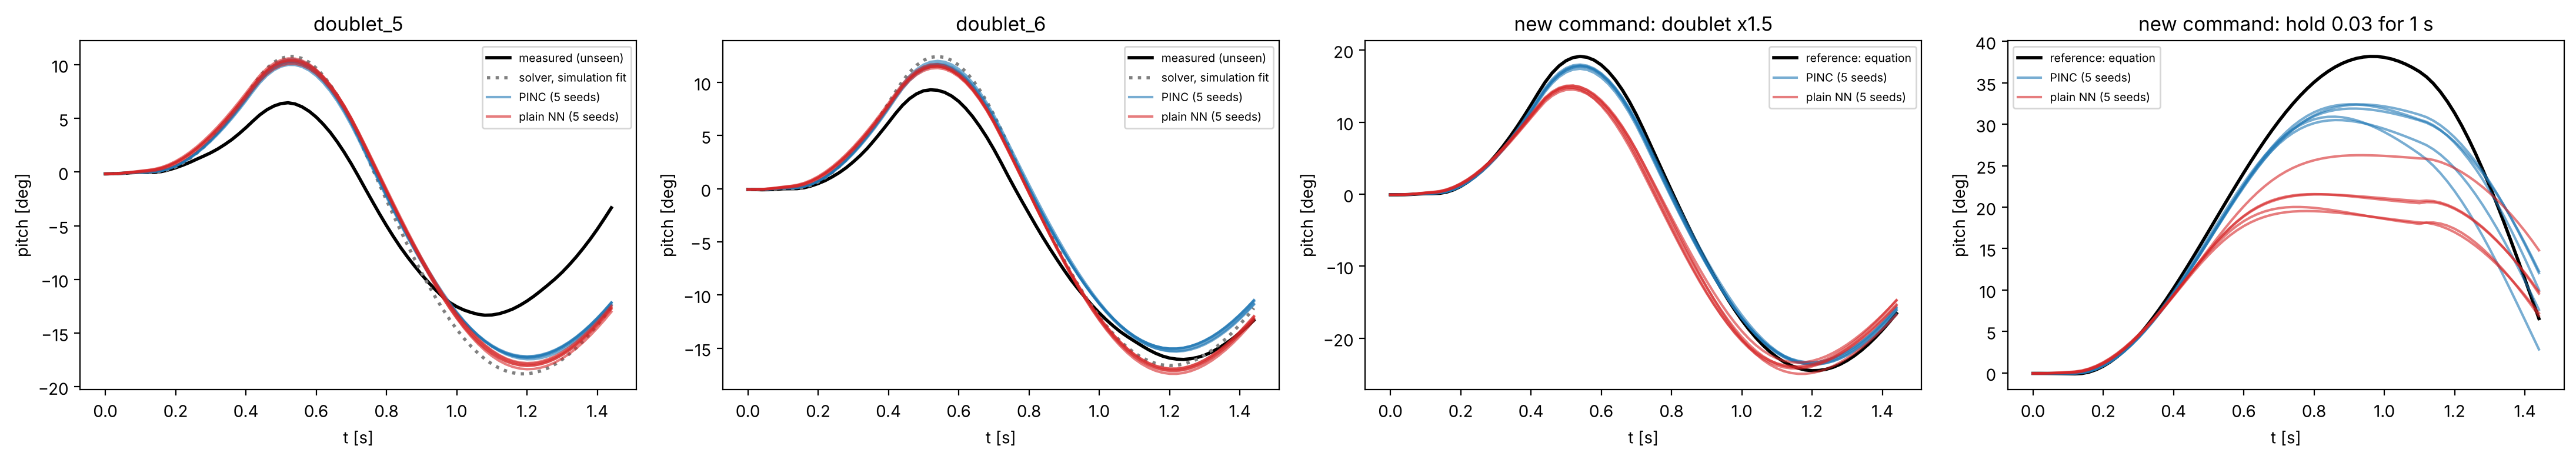

,test,model,VAF
0,doublet_5,"solver, simulation-fit constants",56.1
1,doublet_5,PINC (5 seeds),65.6 ± 1.7
2,doublet_5,plain NN (5 seeds),58.9 ± 2.2
3,doublet_6,"solver, simulation-fit constants",97.4
4,doublet_6,PINC (5 seeds),98.9 ± 0.2
5,doublet_6,plain NN (5 seeds),97.9 ± 0.3
6,new command: doublet x1.5,PINC (5 seeds),99.7 ± 0.1
7,new command: doublet x1.5,plain NN (5 seeds),97.4 ± 0.6
8,new command: hold 0.03 for 1 s,PINC (5 seeds),95.3 ± 1.4
9,new command: hold 0.03 for 1 s,plain NN (5 seeds),76.9 ± 5.4


In [17]:
solver = pitch_model(**P_HOV, tau=0.0)             # delay is already inside u
f6 = HOVER['doublet_6']
M = f6.u.values
NEW = {'doublet x1.5': M[0] + 1.5 * (M - M[0]),
       'hold 0.03 for 1 s': np.where((f6.t > 0.1) & (f6.t < 1.1), M[0] + 0.03, M[0])}
tests = [(n, HOVER[n], None) for n in TEST_HOV] + [('new command: ' + k, f6, u_new) for k, u_new in NEW.items()]

rows = []
fig, ax = plt.subplots(1, 4, figsize=(22, 4))
for a, (name, f, u_new) in zip(ax, tests):
    z_solver = run_flight(solver, f, u_new)[0]
    reference = f.z.values if u_new is None else z_solver      # the measured flight, or the equation for a new command
    a.plot(f.t, np.degrees(reference), 'k', lw=2, label='measured (unseen)' if u_new is None else 'reference: equation')
    if u_new is None:
        a.plot(f.t, np.degrees(z_solver), ':', color='gray', lw=2, label='solver, simulation fit')
        rows.append(dict(test=name, model='solver, simulation-fit constants', VAF=f'{vaf(reference, z_solver):.1f}'))
    for label, color in [('PINC', 'C0'), ('plain NN', 'C3')]:
        v = []
        for i, r in enumerate(RUNS_HOV[label]):
            z = run_flight(r['step'], f, u_new)[0]
            v.append(vaf(reference, z))
            a.plot(f.t, np.degrees(z), color=color, alpha=0.6, label=label + ' (5 seeds)' if i == 0 else None)
        rows.append(dict(test=name, model=label + ' (5 seeds)', VAF=f'{np.mean(v):.1f} ± {np.std(v):.1f}'))
    a.set(title=name, xlabel='t [s]', ylabel='pitch [deg]')
    a.legend(fontsize=7)
plt.tight_layout(); plt.show()

HOVER_TABLE = pd.DataFrame(rows)
HOVER_TABLE.to_csv('final_hover_vaf.csv', index=False)
HOVER_TABLE

## 9. Cart friction (slide 16)
The simulation fit is run twice on the same train flights, matching the cart speed:
- **linear**: only k̄ and c̄;
- **friction**: k̄ and c̄, plus the rubbing force Fc and the level offset θb.

Then each model runs over the whole unseen flight, and both position and speed are scored.

linear   {'kbar': np.float64(3.419), 'cbar': np.float64(1.369)} (40 s)
friction {'kbar': np.float64(3.576), 'cbar': np.float64(0.361), 'Fc': np.float64(0.148), 'thb': np.float64(-0.005)} (46 s)


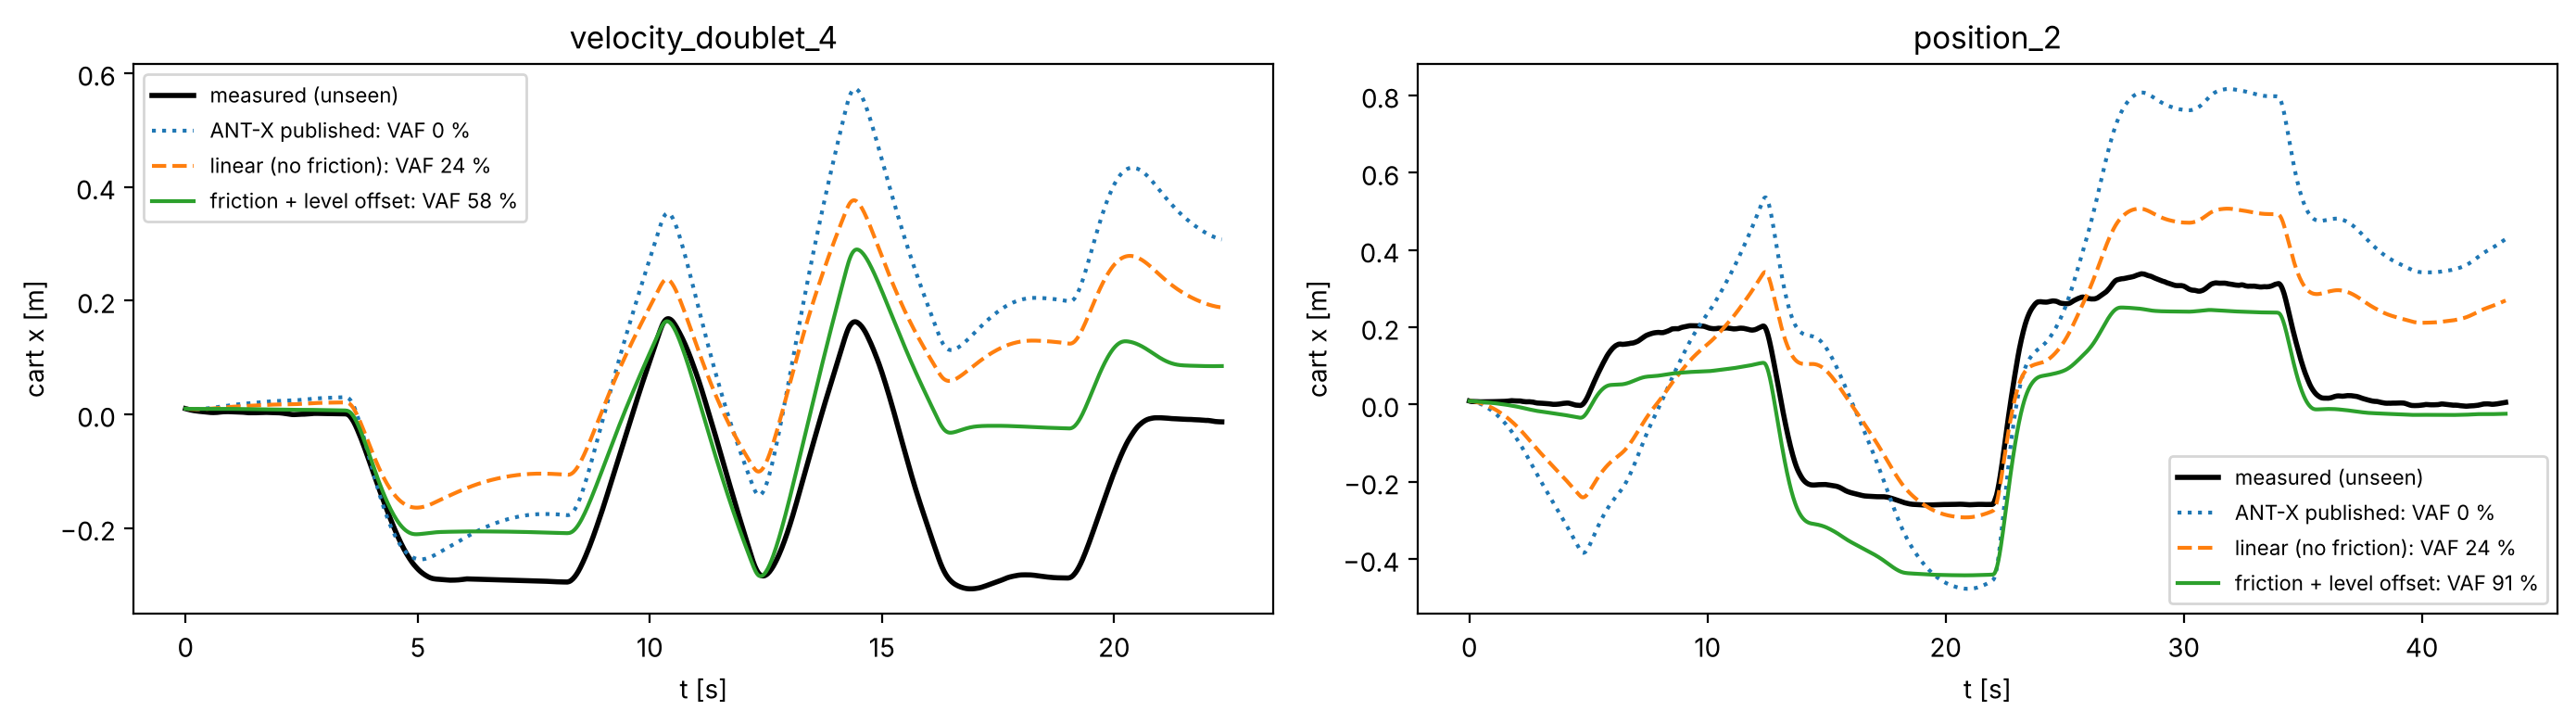

,test,model,VAF_x,VAF_v
0,velocity_doublet_4,ANT-X published,0.0,83.3
1,velocity_doublet_4,linear (no friction),24.2,86.7
2,velocity_doublet_4,friction + level offset,58.4,91.6
3,position_2,ANT-X published,0.0,9.9
4,position_2,linear (no friction),24.1,61.1
5,position_2,friction + level offset,91.1,94.9


In [18]:
TRAIN_CART, TEST_CART = ['velocity_doublet_2', 'velocity_doublet_3', 'position_1', 'position_3'], ['velocity_doublet_4', 'position_2']

lin = train_sim_fit(cart_model, TRAIN_CART, CART, x0=dict(kbar=4.748, cbar=1.168), lo=[0, 0], hi=[50, 20], match='v')
fric = train_sim_fit(cart_model, TRAIN_CART, CART,
                     x0=dict(kbar=lin['constants']['kbar'], cbar=lin['constants']['cbar'], Fc=0.01, thb=0.0),
                     lo=[0, 0, 0, -0.1], hi=[50, 20, 1, 0.1], match='v')
print('linear  ', {k: round(x, 3) for k, x in lin['constants'].items()}, f"({lin['secs']:.0f} s)")
print('friction', {k: round(x, 3) for k, x in fric['constants'].items()}, f"({fric['secs']:.0f} s)")

models = {'ANT-X published': cart_model(kbar=4.748, cbar=1.168),
          'linear (no friction)': cart_model(**lin['constants']),
          'friction + level offset': cart_model(**fric['constants'])}
rows = []
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, n in zip(ax, TEST_CART):
    f = CART[n]
    a.plot(f.t, f.z, 'k', lw=2, label='measured (unseen)')
    for (label, step), style in zip(models.items(), [':', '--', '-']):
        x, v = run_flight(step, f)
        rows.append(dict(test=n, model=label, VAF_x=vaf(f.z.values, x), VAF_v=vaf(f.v.values, v)))
        a.plot(f.t, x, style, label=f"{label}: VAF {rows[-1]['VAF_x']:.0f} %")
    a.set(title=n, xlabel='t [s]', ylabel='cart x [m]')
    a.legend(fontsize=8)
plt.tight_layout(); plt.show()
pd.DataFrame(rows).round(1)

## 10. Summary
- **Job 1.** The simulation fit and the inverse PINN agree closely on ωn, but less on ξ and μ. The ANT-X published constants do not fit our rig, so each rig needs its own constants.
- **Job 2.**
  - With plenty of data (motors off), the plain NN fits best.
  - With little data (hover), and on commands never flown, the PINC is the more reliable of the two. The physics loss keeps it close to the equation where there is no data.
- **2-DOF.**
  - On closed-loop position, the PINC beats the equation on acceleration. It improves further when it learns its own constants (median of 5 seeds).
  - Adding cart friction fixes most of the pitch-driven position model.